# Set 9.2: Train YOLO11 on the blood-cell dataset

**How to use this notebook** (it runs locally, on the GPU of the computer):

1. The repo's `.venv` needs PyTorch with CUDA (the one `requirements.txt` installs is CPU-only on Windows):
   `uv pip install --python .venv/Scripts/python.exe torch torchvision --index-url https://download.pytorch.org/whl/cu132 --reinstall-package torch --reinstall-package torchvision`
2. Unzip the Set 9 datasets into `datasets/` (`blood_cell.v1i.coco/` and, only to check the conversion, `blood_cell.v1i.yolov11/`).
3. Run all cells with the `.venv` kernel. Training 50 epochs from scratch takes about an hour on an RTX 3050 Laptop (4 GB).

At the end the trained detector is saved in `models/` as two files:

| File | What it is |
|---|---|
| `blood_cell_yolo11n.pt` | the best weights (Ultralytics YOLO11 nano, 3 classes) |
| `blood_cell_yolo11n_passport.json` | the **model passport**: dataset, classes, training settings and test metrics |

The full Ultralytics run (curves, confusion matrices, every epoch) stays in `outputs/yolo/`.

In [1]:
import csv
import datetime
import json
import shutil
import time
from collections import Counter
from pathlib import Path

import matplotlib
import numpy as np
import torch
import ultralytics
from matplotlib import pyplot as plt
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
COCO_DIR = ROOT / "datasets" / "blood_cell.v1i.coco"  # what we convert
YOLO_DIR = ROOT / "datasets" / "blood_cell_yolo"  # our conversion
ROBOFLOW_YOLO_DIR = ROOT / "datasets" / "blood_cell.v1i.yolov11"  # Roboflow's own YOLO export, only to check ours
RUNS_DIR = ROOT / "outputs" / "yolo"
MODELS_DIR = ROOT / "models"

SPLITS = ("train", "valid", "test")
CLASSES = ["PC", "RBC", "WBC"]
COLORS = matplotlib.colormaps["tab10"]

RUN_NAME = "from_scratch_50e_v1"
EPOCHS = 50
BATCH = 16
IMAGE_SIZE = 640

assert torch.cuda.is_available(), "PyTorch has no CUDA: install the CUDA build (step 1 above) or training takes many hours"
print("Ultralytics", ultralytics.__version__, "| PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

Ultralytics 8.4.215 | PyTorch 2.15.0+cu132 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## COCO → YOLO conversion

COCO keeps all boxes of a split in one `_annotations.coco.json`, as `[x, y, width, height]` in pixels from the
top-left corner. YOLO wants one `.txt` per image, one line per box: `class_id x_center y_center width height`,
all divided by the image size (so between 0 and 1), with `class_id` from 0.

In this Roboflow export category 0 (`1-2-3-SmhR`) is only the supercategory; PC, RBC and WBC are 1, 2 and 3.
The mapping is built from the class names, so they become 0, 1 and 2.

In [2]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def coco_to_yolo(input_folder, output_folder):
    input_folder, output_folder = Path(input_folder), Path(output_folder)
    images_dir, labels_dir = output_folder / "images", output_folder / "labels"
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    for file in input_folder.iterdir():
        if file.suffix.lower() in IMAGE_EXTENSIONS:
            shutil.copy2(file, images_dir / file.name)

    coco = json.loads((input_folder / "_annotations.coco.json").read_text(encoding="utf-8"))
    class_id = {c["id"]: CLASSES.index(c["name"]) for c in coco["categories"] if c["name"] in CLASSES}
    boxes_of = {}
    for annotation in coco["annotations"]:
        boxes_of.setdefault(annotation["image_id"], []).append(annotation)

    for image in coco["images"]:
        width, height = image["width"], image["height"]
        lines = []
        for annotation in boxes_of.get(image["id"], []):
            x, y, w, h = annotation["bbox"]
            lines.append(
                f"{class_id[annotation['category_id']]} "
                f"{(x + w / 2) / width:.6f} {(y + h / 2) / height:.6f} {w / width:.6f} {h / height:.6f}"
            )
        (labels_dir / (Path(image["file_name"]).stem + ".txt")).write_text("\n".join(lines), encoding="utf-8")
    return len(coco["images"]), len(coco["annotations"])


for split in SPLITS:
    images, boxes = coco_to_yolo(COCO_DIR / split, YOLO_DIR / split)
    print(f"{split:5}: {images} images, {boxes} boxes")

train: 3027 images, 55881 boxes


valid: 288 images, 5361 boxes
test : 144 images, 2678 boxes


Check: our labels should match the YOLO export Roboflow gives for the same dataset (same boxes within 1 px, in any order).

In [3]:
def read_labels(path):
    rows = np.loadtxt(path, ndmin=2) if path.stat().st_size else np.zeros((0, 5))
    return rows[np.lexsort(rows.T[::-1])]


def same_labels(ours, theirs, tolerance=1 / 640):
    # every box must have a box of the same class within 1 px in the other file (the COCO export is rounded)
    if not theirs.exists():
        return False
    a, b = read_labels(ours), read_labels(theirs)
    if a.shape != b.shape:
        return False
    if len(a) == 0:
        return True
    distance = np.abs(a[:, None, 1:] - b[None, :, 1:]).max(axis=2)
    distance[a[:, None, 0] != b[None, :, 0]] = np.inf
    return distance.min(axis=1).max() <= tolerance and distance.min(axis=0).max() <= tolerance


if ROBOFLOW_YOLO_DIR.exists():
    for split in SPLITS:
        ours = sorted((YOLO_DIR / split / "labels").glob("*.txt"))
        different = [p.name for p in ours if not same_labels(p, ROBOFLOW_YOLO_DIR / split / "labels" / p.name)]
        print(f"{split:5}: {len(ours) - len(different)}/{len(ours)} label files match Roboflow's", different[:3])
else:
    print("Roboflow's YOLO export not found, check skipped")

train: 3027/3027 label files match Roboflow's []
valid: 288/288 label files match Roboflow's []


test : 144/144 label files match Roboflow's []


`data.yaml` tells Ultralytics where each split is and the class names.

In [4]:
DATA_YAML = YOLO_DIR / "data.yaml"
DATA_YAML.write_text(
    f"path: {YOLO_DIR.as_posix()}\n"
    "train: train/images\nval: valid/images\ntest: test/images\n\n"
    f"nc: {len(CLASSES)}\nnames: {CLASSES}\n",
    encoding="utf-8",
)
print(DATA_YAML.read_text(encoding="utf-8"))

path: C:/MAI/CV/CV-MAI-2026-27-ForensicsApp/datasets/blood_cell_yolo
train: train/images
val: valid/images
test: test/images

nc: 3
names: ['PC', 'RBC', 'WBC']



## Exploration

Boxes per class in each split, and a few training images with their ground-truth boxes.
The dataset is very unbalanced: almost all boxes are red blood cells.

train: {'PC': 1803, 'RBC': 50895, 'WBC': 3183}
valid: {'PC': 159, 'RBC': 4895, 'WBC': 307}
test : {'PC': 91, 'RBC': 2439, 'WBC': 148}


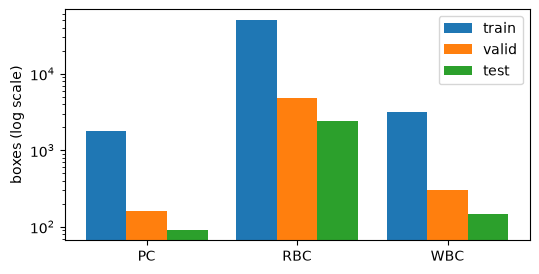

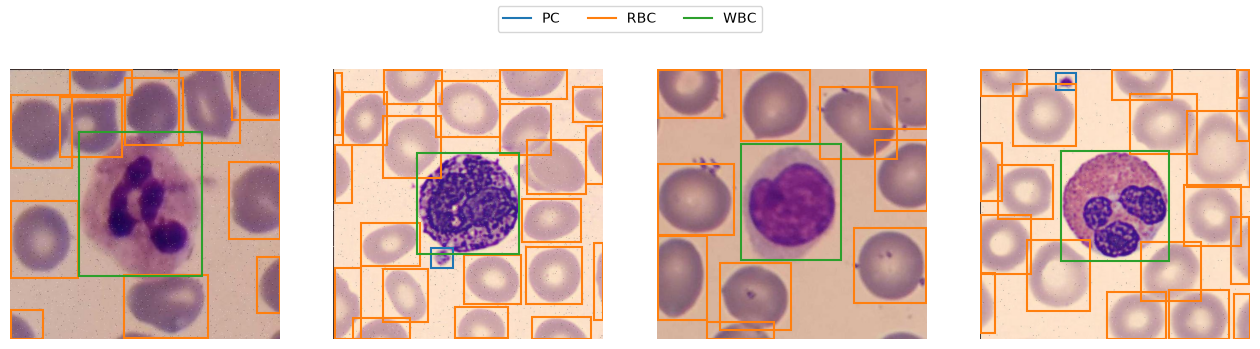

In [5]:
counts = {}
for split in SPLITS:
    counts[split] = Counter(int(row[0]) for p in (YOLO_DIR / split / "labels").glob("*.txt") for row in read_labels(p))
    print(f"{split:5}:", {CLASSES[c]: counts[split][c] for c in range(len(CLASSES))})

fig, ax = plt.subplots(figsize=(6, 3))
for i, split in enumerate(SPLITS):
    ax.bar(np.arange(len(CLASSES)) + (i - 1) * 0.27, [counts[split][c] for c in range(len(CLASSES))], 0.27, label=split)
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yscale("log")
ax.set_ylabel("boxes (log scale)")
ax.legend()
plt.show()


def draw_boxes(ax, image_path, label_path, linewidth=1.5):
    image = plt.imread(image_path)
    height, width = image.shape[:2]
    ax.imshow(image)
    for c, xc, yc, w, h in read_labels(label_path):
        ax.add_patch(plt.Rectangle(((xc - w / 2) * width, (yc - h / 2) * height), w * width, h * height,
                                   fill=False, edgecolor=COLORS(int(c)), linewidth=linewidth))
    ax.axis("off")


train_images = sorted((YOLO_DIR / "train" / "images").iterdir())
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, image_path in zip(axes, train_images[::len(train_images) // 4]):
    draw_boxes(ax, image_path, YOLO_DIR / "train" / "labels" / (image_path.stem + ".txt"))
fig.legend(handles=[plt.Line2D([], [], color=COLORS(c), label=name) for c, name in enumerate(CLASSES)], loc="upper center", ncol=3)
plt.show()

## Training YOLO11 nano from scratch

`yolo11n.yaml` builds the network with random weights (no COCO pretraining), as in the slides.
Batch 16 at 640 × 640 fits in 4 GB of GPU memory.

In [6]:
model = YOLO("yolo11n.yaml")
start = time.time()
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMAGE_SIZE,
    classes=[0, 1, 2],
    plots=True,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    device=0,
    workers=4,
    seed=0,
)
TRAIN_MINUTES = (time.time() - start) / 60
RUN_DIR = Path(model.trainer.save_dir)
print(f"Trained in {TRAIN_MINUTES:.0f} min, run saved in {RUN_DIR}")

Ultralytics 8.4.215  Python-3.13.11 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=[0, 1, 2], close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\datasets\blood_cell_yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=from_scratch_50e_v1, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_m

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (10,130 outputs left out)

                   WBC        286        307       0.99      0.971       0.98      0.859


Speed: 0.3ms preprocess, 3.0ms inference, 0.0ms loss, 2.2ms postprocess per image


Results saved to C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\outputs\yolo\from_scratch_50e_v1


Trained in 31 min, run saved in C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\outputs\yolo\from_scratch_50e_v1


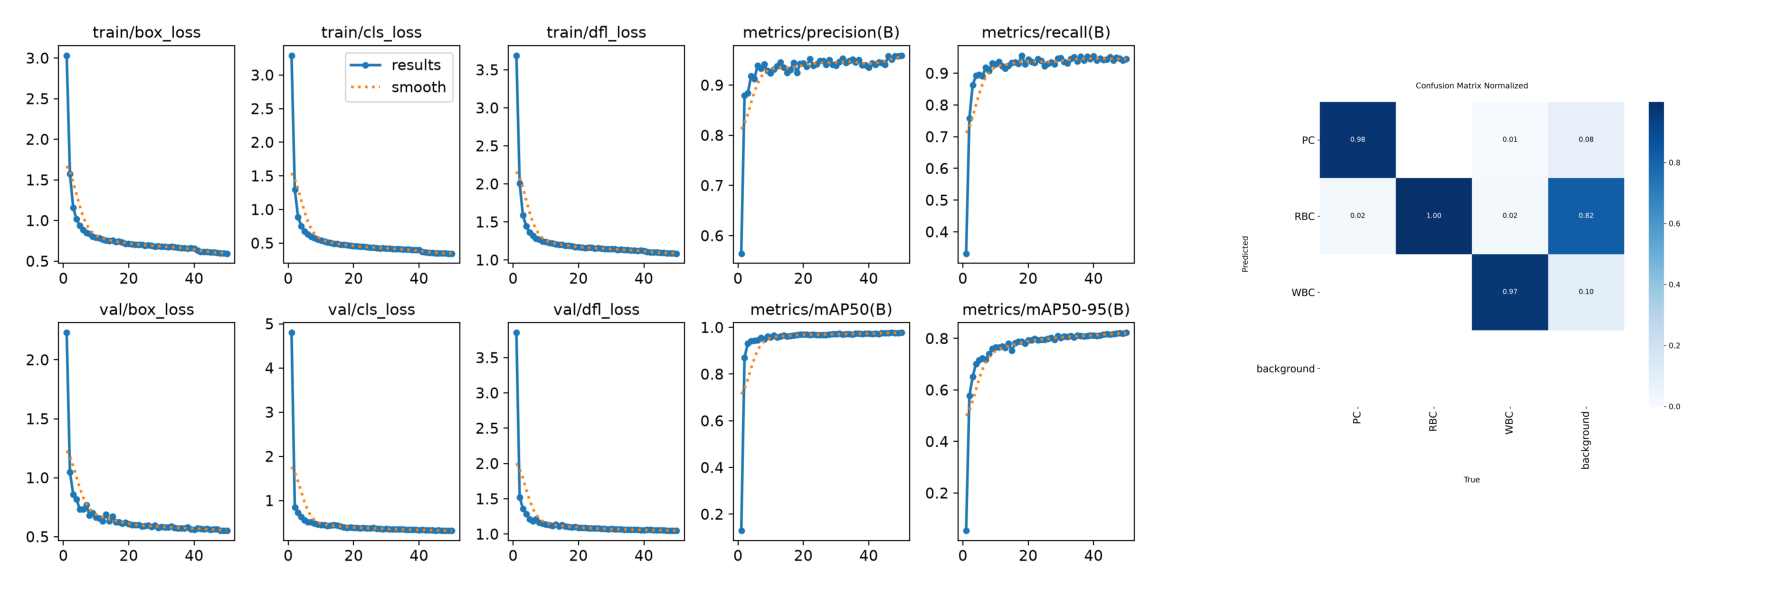

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), width_ratios=[2, 1])
for ax, name in zip(axes, ["results.png", "confusion_matrix_normalized.png"]):
    ax.imshow(plt.imread(RUN_DIR / name))
    ax.axis("off")
plt.tight_layout()
plt.show()

## Test set evaluation

The 144 test images were never used for training or for choosing the best epoch.

In [8]:
best = YOLO(RUN_DIR / "weights" / "best.pt")
metrics = best.val(data=str(DATA_YAML), split="test", batch=BATCH, imgsz=IMAGE_SIZE, device=0,
                   project=str(RUNS_DIR), name=RUN_NAME + "_test", plots=True)
TEST = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "per_class": {CLASSES[int(c)]: {"mAP50": float(metrics.box.ap50[i]), "mAP50_95": float(metrics.box.ap[i])}
                  for i, c in enumerate(metrics.box.ap_class_index)},
}
print(json.dumps(TEST, indent=2))

Ultralytics 8.4.215  Python-3.13.11 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs


WARNING val: Slow image access detected (ping: 0.2±0.1 ms, read: 39.2±23.0 MB/s, size: 26.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips


val: Scanning C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\datasets\blood_cell_yolo\test\labels... 61 images, 0 backgrounds, 0 corrupt: 42% ━━━━━─────── 61/144 180.2it/s 0.1s<0.5s

val: Scanning C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\datasets\blood_cell_yolo\test\labels... 131 images, 0 backgrounds, 0 corrupt: 90% ━━━━━━━━━━╸─ 131/144 333.0it/s 0.2s<0.0s

val: Scanning C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\datasets\blood_cell_yolo\test\labels... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 669.9it/s 0.2s

... (13 outputs left out)

                   WBC        143        148      0.979      0.986      0.991      0.874


Speed: 1.6ms preprocess, 6.7ms inference, 0.0ms loss, 1.7ms postprocess per image


Results saved to C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\outputs\yolo\from_scratch_50e_v1_test


{
  "precision": 0.9638475096658361,
  "recall": 0.9592213964907691,
  "mAP50": 0.984511778793998,
  "mAP50_95": 0.840683532763448,
  "per_class": {
    "PC": {
      "mAP50": 0.9717585501550269,
      "mAP50_95": 0.7624507326385991
    },
    "RBC": {
      "mAP50": 0.9904063643706313,
      "mAP50_95": 0.8853711949415592
    },
    "WBC": {
      "mAP50": 0.9913704218563354,
      "mAP50_95": 0.874228670710186
    }
  }
}


Ground truth (left) and prediction (right) on a few test images.

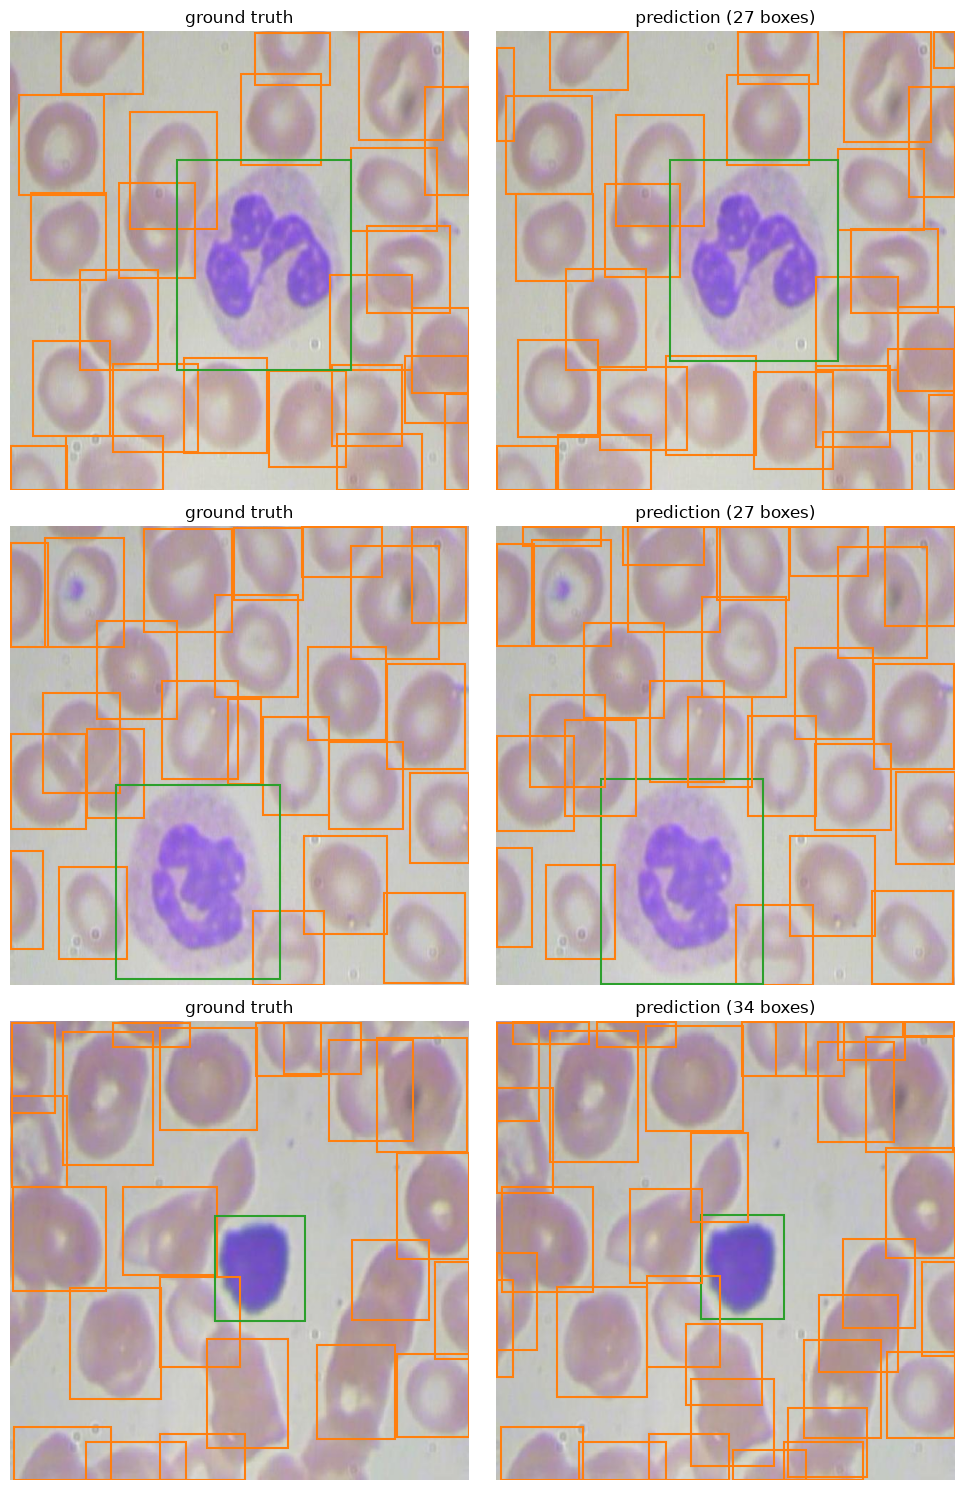

In [9]:
test_images = sorted((YOLO_DIR / "test" / "images").iterdir())[:3]
fig, axes = plt.subplots(len(test_images), 2, figsize=(10, 5 * len(test_images)))
for row, image_path in zip(axes, test_images):
    draw_boxes(row[0], image_path, YOLO_DIR / "test" / "labels" / (image_path.stem + ".txt"))
    row[0].set_title("ground truth")
    result = best.predict(image_path, imgsz=IMAGE_SIZE, device=0, verbose=False)[0]
    row[1].imshow(plt.imread(image_path))
    for (x1, y1, x2, y2), c in zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist()):
        row[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=COLORS(int(c)), linewidth=1.5))
    row[1].set_title(f"prediction ({len(result.boxes)} boxes)")
    row[1].axis("off")
plt.tight_layout()
plt.show()

## Save weights + passport

In [10]:
MODELS_DIR.mkdir(exist_ok=True)
weights = MODELS_DIR / "blood_cell_yolo11n.pt"
shutil.copy2(RUN_DIR / "weights" / "best.pt", weights)

with open(RUN_DIR / "results.csv", newline="") as f:
    history = [{k.strip(): float(v) for k, v in row.items()} for row in csv.DictReader(f)]
best_epoch = max(history, key=lambda r: 0.1 * r["metrics/mAP50(B)"] + 0.9 * r["metrics/mAP50-95(B)"])  # Ultralytics' fitness


def split_size(split):
    labels = list((YOLO_DIR / split / "labels").glob("*.txt"))
    return {"images": len(labels), "boxes": sum(counts[split].values())}


passport = {
    "name": "Blood-cell detector (YOLO11 nano, trained from scratch)",
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "framework": f"Ultralytics {ultralytics.__version__}, PyTorch {torch.__version__}",
    "files": {"weights": weights.name},
    "architecture": {"model": "yolo11n.yaml", "pretrained": False,
                     "parameters": sum(p.numel() for p in best.model.parameters())},
    "dataset": {
        "name": "Blood cell detection (Roboflow tumor-4iauk/blood-cell-st9na v1)",
        "source": "https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na",
        "license": "CC BY 4.0",
        "format": "COCO converted to YOLO with coco_to_yolo",
        **{split: split_size(split) for split in SPLITS},
        "boxes_per_class": {split: {CLASSES[c]: counts[split][c] for c in range(len(CLASSES))} for split in SPLITS},
    },
    "classes": CLASSES,
    "preprocessing": {"input_size": [IMAGE_SIZE, IMAGE_SIZE], "note": "Ultralytics letterboxes and scales the image itself"},
    "training": {
        "epochs": EPOCHS, "batch_size": BATCH, "image_size": IMAGE_SIZE, "seed": 0,
        "device": torch.cuda.get_device_name(0), "minutes": round(TRAIN_MINUTES, 1),
        "best_epoch": int(best_epoch["epoch"]),
        "history": history,
    },
    "evaluation": {"split": "test", **TEST},
}
passport_path = MODELS_DIR / "blood_cell_yolo11n_passport.json"
passport_path.write_text(json.dumps(passport, indent=2), encoding="utf-8")
print("Saved", weights, "and", passport_path)

Saved C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\models\blood_cell_yolo11n.pt and C:\MAI\CV\CV-MAI-2026-27-ForensicsApp\models\blood_cell_yolo11n_passport.json
